# 1. Research Question
Do traders executing many small transactions show different **overall profitability** patterns from traders executing fewer large transactions? Does trading frequency interact with average transaction size in its association with profitability?

The primary outcome is `trader_ppv` (profit per unit of trading volume); `trader_pnl` (total profit or loss) is secondary. This is an exploratory trader-level observational analysis, not a causal strategy evaluation.

# 2. Data Loading
Run this notebook from the folder containing `data_no_imputation.parquet`. Required packages: pandas, NumPy, Matplotlib, SciPy, statsmodels, pyarrow (or another pandas Parquet engine), and IPython/Jupyter. No variables from another notebook are used. The source Parquet file is only read.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
import statsmodels.api as sm
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_parquet("data_no_imputation.parquet")
print('Dataset shape:', df.shape)
required = ['transactions_per_day', 'mean_tx_value', 'transaction_count',
            'trader_ppv', 'trader_pnl', 'trader_volume']
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')
print('All required columns exist.')
display(df[required].dtypes.rename('dtype').to_frame())

Dataset shape: (524760, 41)
All required columns exist.


,dtype
transactions_per_day,float64
mean_tx_value,float64
transaction_count,uint32
trader_ppv,float64
trader_pnl,float64
trader_volume,float64


# 3. Data Preparation
Keep traders with at least 100 transactions and finite, nonmissing values in all six required columns. Both outcomes use this common sample. Missing unrelated variables do not exclude traders. Preserve every extreme finite observation; do not trim, winsorize, impute, or modify the source data. All group summaries weight traders equally.

In [2]:
numeric = df[required].apply(pd.to_numeric, errors='raise')
eligible = numeric.transaction_count.ge(100)
finite = np.isfinite(numeric.to_numpy(dtype=float, na_value=np.nan)).all(axis=1)
analysis = numeric.loc[eligible & finite].copy()
print(f'Traders meeting transaction threshold: {eligible.sum():,}')
print(f'Removed for missing/infinite relevant values: {(eligible & ~finite).sum():,}')
print(f'Traders remaining after filtering: {len(analysis):,}')
if len(analysis) < 10:
    raise ValueError('Insufficient traders for the planned analysis.')
if 'trader' in df:
    ids = df.loc[analysis.index, 'trader']
    if ids.isna().any() or ids.duplicated().any():
        raise ValueError('Resolve missing/duplicate trader IDs before assuming one independent trader per row.')
else:
    print('No trader ID: one independent trader per row remains an assumption.')
display(analysis.describe(percentiles=[.01, .25, .5, .75, .99]).T)
print('Predictor skewness:')
print(analysis[['transactions_per_day', 'mean_tx_value']].skew())

Traders meeting transaction threshold: 21,323
Removed for missing/infinite relevant values: 0
Traders remaining after filtering: 21,323
Predictor skewness:
transactions_per_day    24.785033
mean_tx_value            9.589338
dtype: float64


,count,mean,std,min,1%,25%,50%,75%,99%,max
transactions_per_day,21323.0,26.774278,7.221345e+01,1.104000e+00,2.191818,6.157895,10.500000,22.222222,2.105538e+02,4.805647e+03
mean_tx_value,21323.0,121.769645,2.601429e+02,1.745374e-02,0.964691,15.355537,51.324321,118.918250,1.125636e+03,9.624208e+03
transaction_count,21323.0,893.625756,6.023782e+03,1.000000e+02,100.000000,129.500000,199.000000,436.000000,1.168204e+04,4.194990e+05
trader_ppv,21323.0,-0.006120,5.411099e-02,-6.069192e-01,-0.173394,-0.018007,-0.001538,0.006262,1.467419e-01,7.546843e-01
trader_pnl,21323.0,726.350952,3.340998e+04,-1.219870e+06,-47457.479444,-489.198832,-5.370294,125.470769,6.267729e+04,1.103256e+06
trader_volume,21323.0,261244.639229,1.635295e+06,1.150648e+01,280.313063,6730.999447,25043.996783,98113.007204,4.213445e+06,9.157941e+07


# 4. Four-Group Trading Strategy Analysis
The medians are calculated on the final analysis sample. Frequency **at or below** its median is low; strictly above is high. Transaction size **at or below** its median is small; strictly above is large. This assigns median ties consistently to exactly one group. Ties and dependence between the predictors mean group counts need not be equal.

In [3]:
frequency_median = analysis.transactions_per_day.median()
size_median = analysis.mean_tx_value.median()
print(f'Frequency median: {frequency_median:.6g} transactions/day')
print(f'Transaction-size median: {size_median:.6g} (dataset value units)')
print('Frequency median ties:', int(analysis.transactions_per_day.eq(frequency_median).sum()))
print('Size median ties:', int(analysis.mean_tx_value.eq(size_median).sum()))
frequency_order, size_order = ['Low', 'High'], ['Small', 'Large']
analysis['frequency_group'] = pd.Categorical(np.where(analysis.transactions_per_day <= frequency_median, 'Low', 'High'), categories=frequency_order, ordered=True)
analysis['size_group'] = pd.Categorical(np.where(analysis.mean_tx_value <= size_median, 'Small', 'Large'), categories=size_order, ordered=True)

def summarize(data, keys):
    return data.groupby(keys, observed=False).agg(
        n_traders=('trader_ppv', 'size'), mean_ppv=('trader_ppv', 'mean'),
        median_ppv=('trader_ppv', 'median'), std_ppv=('trader_ppv', 'std'),
        mean_pnl=('trader_pnl', 'mean'), median_pnl=('trader_pnl', 'median'))

four_summary = summarize(analysis, ['frequency_group', 'size_group'])
assert four_summary.n_traders.sum() == len(analysis)
assert analysis[['frequency_group', 'size_group']].notna().all().all()
display(four_summary)

# Use a common symmetric color scale for all PPV heatmaps, defined from all cell summaries below.
def heatmap(matrix, title, xlabel, ylabel, count=False, limit=None):
    values = matrix.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(max(7, 1.6 * matrix.shape[1]), max(4.5, .9 * matrix.shape[0])) )
    cmap = plt.get_cmap('viridis' if count else 'RdBu_r').copy()
    cmap.set_bad('#dddddd')
    options = {}
    if not count:
        bound = limit if limit is not None else max(float(np.nanmax(np.abs(values))), 1e-12)
        options['norm'] = TwoSlopeNorm(vmin=-bound, vcenter=0, vmax=bound)
    im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, aspect='auto', **options)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            label = 'NA' if np.isnan(v) else (f'{v:,.0f}' if count else f'{v:.5f}')
            rgba = im.cmap(im.norm(v)) if np.isfinite(v) else (1, 1, 1, 1)
            color = 'black' if np.dot(rgba[:3], [.299, .587, .114]) > .55 else 'white'
            ax.text(j, i, label, ha='center', va='center', color=color)
    fig.colorbar(im, ax=ax, label='Number of traders' if count else 'Overall trader_ppv')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

four_limit = max(float(four_summary[['mean_ppv','median_ppv']].abs().max().max()), 1e-12)

Frequency median: 10.5 transactions/day
Transaction-size median: 51.3243 (dataset value units)
Frequency median ties: 25
Size median ties: 1


n_traders  mean_ppv  ...     mean_pnl  median_pnl
frequency_group size_group                       ...                         
Low             Small            6750 -0.007172  ...   -60.986699   -7.231616
                Large            3933 -0.004480  ...   193.616628  -80.480938
High            Small            3912 -0.005868  ...   -44.594131   -5.193764
                Large            6728 -0.006169  ...  2275.951190   -0.680165

[4 rows x 6 columns]

### Chart 1: Median Profitability Heatmap

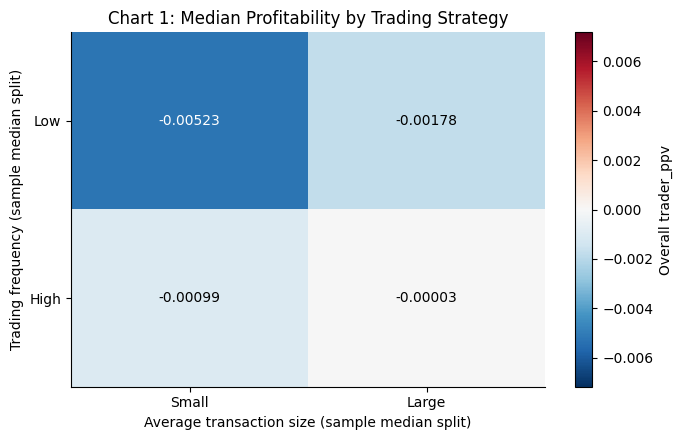

In [4]:
heatmap(four_summary['median_ppv'].unstack('size_group'),
        'Chart 1: Median Profitability by Trading Strategy',
        'Average transaction size (sample median split)', 'Trading frequency (sample median split)',
        count=False, limit=four_limit)

### Chart 2: Mean Profitability Heatmap

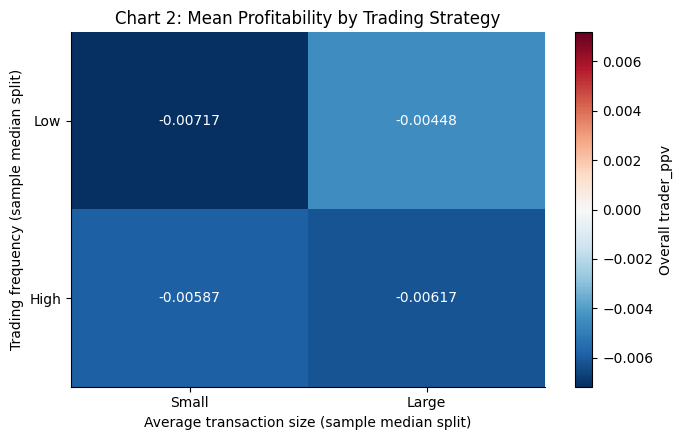

In [5]:
heatmap(four_summary['mean_ppv'].unstack('size_group'),
        'Chart 2: Mean Profitability by Trading Strategy',
        'Average transaction size (sample median split)', 'Trading frequency (sample median split)',
        count=False, limit=four_limit)

### Chart 3: Trader Count Heatmap

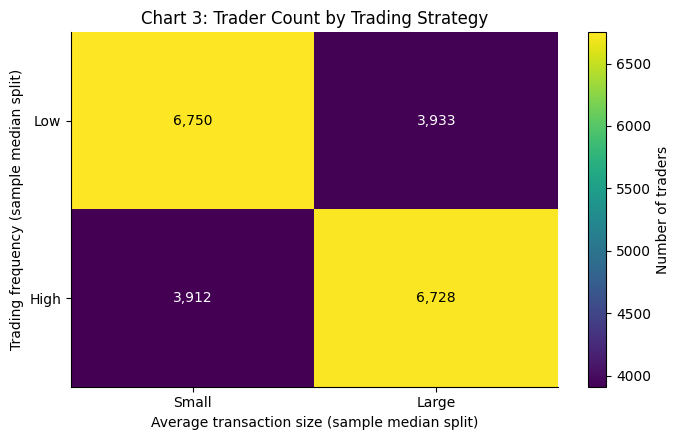

In [6]:
heatmap(four_summary['n_traders'].unstack('size_group'),
        'Chart 3: Trader Count by Trading Strategy',
        'Average transaction size (sample median split)', 'Trading frequency (sample median split)',
        count=True, limit=four_limit)

### Chart 4: Profitability Distribution
Boxes show quartiles and medians; whiskers extend to the most extreme data within 1.5 interquartile ranges. All remaining finite observations are plotted as outlier points. This display convention does not remove them from the data or summaries. The full PPV range is retained.

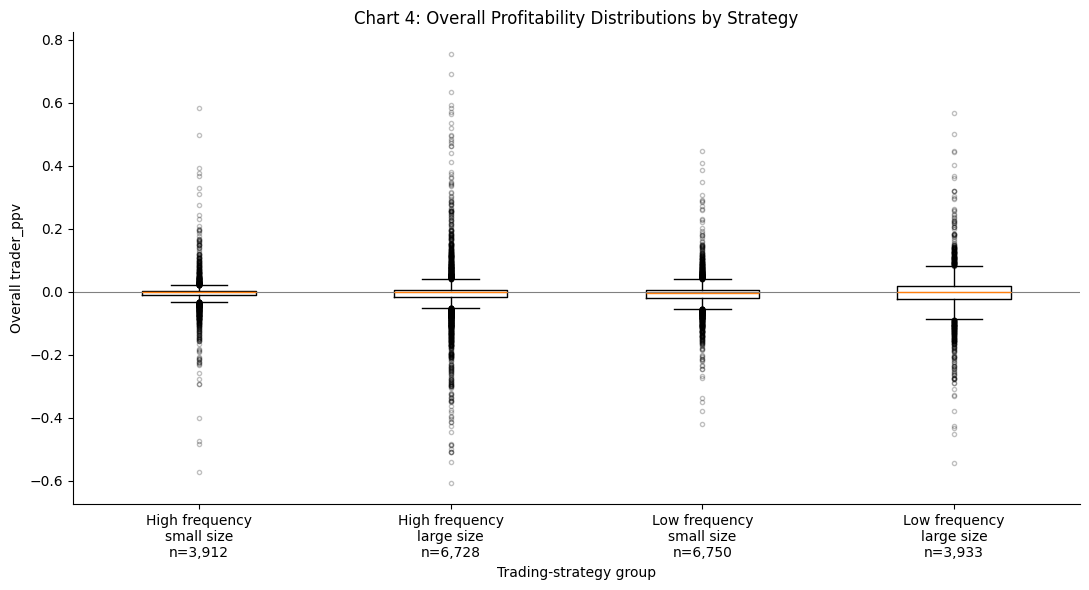

In [7]:
group_order = [('High', 'Small'), ('High', 'Large'), ('Low', 'Small'), ('Low', 'Large')]
group_values = [analysis.loc[(analysis.frequency_group == f) & (analysis.size_group == s), 'trader_ppv'].to_numpy() for f, s in group_order]
fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(group_values, showfliers=True, flierprops={'markersize': 3, 'alpha': .25})
ax.set_xticks(range(1, 5), [f'{f} frequency\n{s.lower()} size\nn={len(v):,}' for (f, s), v in zip(group_order, group_values)])
ax.axhline(0, color='gray', lw=.8)
ax.set(title='Chart 4: Overall Profitability Distributions by Strategy', xlabel='Trading-strategy group', ylabel='Overall trader_ppv')
fig.tight_layout()
plt.show()
plt.close(fig)

# 5. Detailed Trading Strategy Heatmaps
Calculate frequency and size quintiles independently, using the whole filtered sample rather than within other groups. Duplicate quantile boundaries are dropped; identical values are never split arbitrarily. If this produces fewer than five groups, report the reduction and use the actual grid dimensions. A constant predictor forms one group. Bin tables show the precise boundaries (first interval includes both endpoints, subsequent intervals are left-open/right-closed).

Empty cells have zero traders and missing profitability (`NA`), never zero profitability. Sparse cells are descriptive and potentially unstable. Means and medians within each grid share a zero-centered color scale; the 2?2 and detailed grids may have different scales.

In [8]:
def quantile_groups(series, name):
    if series.nunique() == 1:
        groups = pd.Series(pd.Categorical(['Q1'] * len(series), categories=['Q1'], ordered=True), index=series.index)
        bounds = pd.DataFrame({'group': ['Q1'], 'lower': [series.iloc[0]], 'upper': [series.iloc[0]]})
    else:
        _, edges = pd.qcut(series, q=5, duplicates='drop', retbins=True)
        names = [f'Q{i+1}' for i in range(len(edges)-1)]
        groups = pd.cut(series, edges, labels=names, include_lowest=True, right=True)
        bounds = pd.DataFrame({'group': names, 'lower': edges[:-1], 'upper': edges[1:]})
    actual = len(groups.cat.categories)
    print(f'{name}: {actual} quantile groups. ' + ('Duplicate boundaries/constant values prevent five distinct groups.' if actual < 5 else 'Five distinct groups available.'))
    bounds['n_traders'] = groups.value_counts(sort=False).to_numpy()
    display(bounds)
    assert groups.notna().all()
    return groups

analysis['frequency_quantile'] = quantile_groups(analysis.transactions_per_day, 'Trading frequency')
analysis['size_quantile'] = quantile_groups(analysis.mean_tx_value, 'Average transaction size')
detailed_summary = summarize(analysis, ['frequency_quantile', 'size_quantile'])
assert detailed_summary.n_traders.sum() == len(analysis)
display(detailed_summary)
detailed_limit = max(float(detailed_summary[['mean_ppv', 'median_ppv']].abs().max().max()), 1e-12)

Trading frequency: 5 quantile groups. Five distinct groups available.
Average transaction size: 5 quantile groups. Five distinct groups available.


,group,lower,upper,n_traders
0,Q1,1.104000,5.511288,4265
1,Q2,5.511288,8.333333,4296
2,Q3,8.333333,13.465164,4233
3,Q4,13.465164,29.038117,4264
4,Q5,29.038117,4805.647059,4265


,group,lower,upper,n_traders
0,Q1,0.017454,9.722622,4265
1,Q2,9.722622,36.903803,4264
2,Q3,36.903803,68.094873,4265
3,Q4,68.094873,152.554299,4264
4,Q5,152.554299,9624.207540,4265


n_traders  ...   median_pnl
frequency_quantile size_quantile             ...             
Q1                 Q1                  1401  ...    -4.453053
                   Q2                  1321  ...   -26.072625
                   Q3                   665  ...   -23.234157
                   Q4                   566  ...    -9.505096
                   Q5                   312  ...   257.532368
Q2                 Q1                  1329  ...    -2.460916
                   Q2                   987  ...   -71.584846
                   Q3                   593  ...  -119.511147
                   Q4                   782  ...  -190.044533
                   Q5                   605  ...   -53.421644
Q3                 Q1                   745  ...   -12.321127
                   Q2                   833  ...   -81.767037
                   Q3                   705  ...  -178.422759
                   Q4                   914  ...  -252.423602
                   Q5                  1036  ...  -118.559457
Q4                 Q1                   426  ...    -9.856578
                   Q2                   657  ...   -89.955418
                   Q3                   829  ...   -15.629480
                   Q4                   973  ...  -295.848222
                   Q5                  1379  ... -1070.510660
Q5                 Q1                   364  ...    -0.848124
                   Q2                   466  ...    -0.048860
                   Q3                  1473  ...    -0.008710
                   Q4                  1029  ...    -0.095000
                   Q5                   933  ... -1449.150469

[25 rows x 6 columns]

### Chart 5: Detailed Median Profitability Heatmap

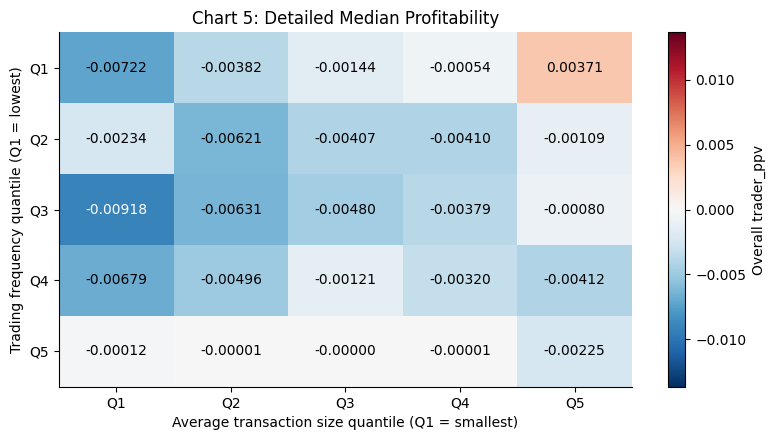

In [9]:
heatmap(detailed_summary['median_ppv'].unstack('size_quantile'),
        'Chart 5: Detailed Median Profitability', 'Average transaction size quantile (Q1 = smallest)',
        'Trading frequency quantile (Q1 = lowest)', count=False, limit=detailed_limit)

### Chart 6: Detailed Mean Profitability Heatmap

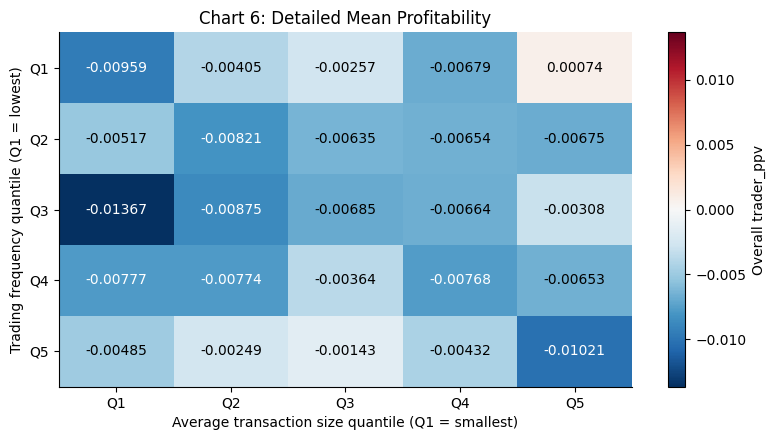

In [10]:
heatmap(detailed_summary['mean_ppv'].unstack('size_quantile'),
        'Chart 6: Detailed Mean Profitability', 'Average transaction size quantile (Q1 = smallest)',
        'Trading frequency quantile (Q1 = lowest)', count=False, limit=detailed_limit)

### Chart 7: Detailed Trader Count Heatmap

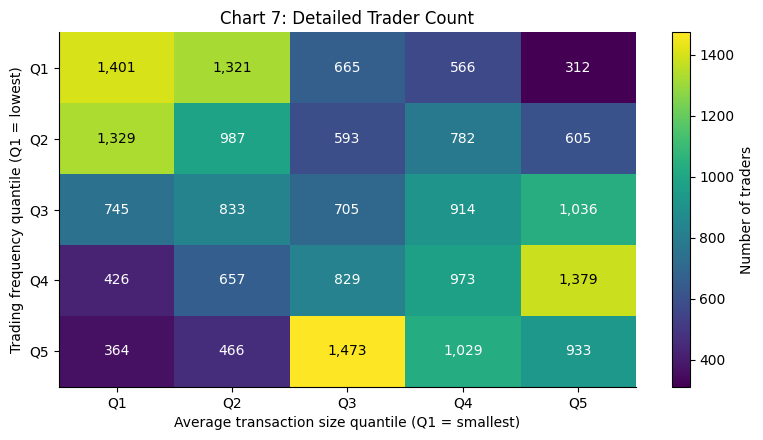

In [11]:
heatmap(detailed_summary['n_traders'].unstack('size_quantile'),
        'Chart 7: Detailed Trader Count', 'Average transaction size quantile (Q1 = smallest)',
        'Trading frequency quantile (Q1 = lowest)', count=True, limit=detailed_limit)

# 6. Statistical Analysis
### Interaction regression
Fit OLS with an intercept, centered `log1p(transactions_per_day)`, centered `log1p(mean_tx_value)`, and their product. Log transforms reduce predictor skew without discarding high values; outcomes remain in original units, including negative PNL. If a future dataset has negative predictors, use signed `log1p(abs(x))` and flag the definition issue rather than remove finite rows. Logs depend on the recorded measurement units.

Use **HC3 heteroskedasticity-robust standard errors**, normal-reference 95% confidence intervals, and two-sided p-values. HC3 does not remove sensitivity of OLS coefficients to extremes or resolve dependence between traders. Main effects describe slopes when the other transformed predictor is at its sample mean. The interaction is the change in one transformed-predictor slope per unit increase in the other. It is not a comparison of four median-split groups, nor a raw-scale interaction coefficient.

Fit PPV as primary and raw PNL as secondary, and report Bonferroni-adjusted interaction p-values across these two tests. Other coefficient p-values and confidence intervals are nominal. The model is unadjusted: trading experience, market selection, capital, and other confounders may influence associations.

In [12]:
predictors = pd.DataFrame(index=analysis.index)
for source, target in [('transactions_per_day', 'log_frequency_c'), ('mean_tx_value', 'log_size_c')]:
    x = analysis[source]
    if (x < 0).any():
        print(f'WARNING: negative {source}; using signed log1p and retaining finite rows. Inspect variable definitions.')
        transformed = np.sign(x) * np.log1p(np.abs(x))
    else:
        transformed = np.log1p(x)
    predictors[target] = transformed - transformed.mean()
    print(f'{source}: skewness raw={stats.skew(x, bias=False):.3f}, transformed={stats.skew(transformed, bias=False):.3f}')
predictors['interaction'] = predictors.log_frequency_c * predictors.log_size_c
X = sm.add_constant(predictors, has_constant='add')
if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
    raise ValueError('Interaction design is rank deficient; independent effects cannot be estimated.')
models, coefficient_tables = {}, {}
interaction_rows = []
for outcome in ['trader_ppv', 'trader_pnl']:
    fitted = sm.OLS(analysis[outcome], X).fit(cov_type='HC3', use_t=False)
    models[outcome] = fitted
    ci = fitted.conf_int(alpha=.05)
    table = pd.DataFrame({'coefficient': fitted.params, 'robust_se_HC3': fitted.bse,
                          'ci95_low': ci[0], 'ci95_high': ci[1], 'p_value': fitted.pvalues})
    table['n_traders'] = int(fitted.nobs)
    coefficient_tables[outcome] = table
    print(f'{outcome}: OLS with HC3 SE; n={int(fitted.nobs):,}; R-squared={fitted.rsquared:.4f}')
    display(table)
    interaction_rows.append({'outcome': outcome, 'interaction_coefficient': fitted.params['interaction'],
                             'p_value': fitted.pvalues['interaction'], 'n_traders': int(fitted.nobs)})
interaction_tests = pd.DataFrame(interaction_rows)
interaction_tests['p_bonferroni'] = (2 * interaction_tests.p_value).clip(upper=1)
display(interaction_tests)

# Translate the interaction into conditional slopes at observed predictor quartiles.
conditional_rows = []
for outcome, fitted in models.items():
    for focal, other in [('log_frequency_c', 'log_size_c'), ('log_size_c', 'log_frequency_c')]:
        for quantile in [.25, .5, .75]:
            level = predictors[other].quantile(quantile)
            contrast = pd.Series(0.0, index=X.columns)
            contrast[focal], contrast['interaction'] = 1.0, level
            estimate = float(contrast @ fitted.params)
            se = float(np.sqrt(contrast @ fitted.cov_params() @ contrast))
            conditional_rows.append({'outcome': outcome, 'slope_for': focal, 'other_predictor_quantile': quantile,
                                     'slope': estimate, 'ci95_low': estimate-1.96*se, 'ci95_high': estimate+1.96*se})
print('Conditional slopes per transformed-predictor unit; pointwise 95% intervals:')
conditional_slopes = pd.DataFrame(conditional_rows)
display(conditional_slopes)

transactions_per_day: skewness raw=24.785, transformed=1.003
mean_tx_value: skewness raw=9.589, transformed=-0.167
trader_ppv: OLS with HC3 SE; n=21,323; R-squared=0.0008
trader_pnl: OLS with HC3 SE; n=21,323; R-squared=0.0076
Conditional slopes per transformed-predictor unit; pointwise 95% intervals:


,coefficient,robust_se_HC3,ci95_low,ci95_high,p_value,n_traders
const,-0.005872,0.000374,-0.006606,-0.005138,1.987260e-55,21323
log_frequency_c,0.000290,0.000357,-0.000410,0.000990,4.170197e-01,21323
log_size_c,0.000671,0.000323,0.000038,0.001305,3.787006e-02,21323
interaction,-0.000651,0.000358,-0.001354,0.000051,6.908150e-02,21323


,coefficient,robust_se_HC3,ci95_low,ci95_high,p_value,n_traders
const,97.255945,132.891819,-163.207234,357.719124,0.464264,21323
log_frequency_c,1630.868654,456.777261,735.601673,2526.135635,0.000356,21323
log_size_c,770.889770,306.539010,170.084350,1371.695190,0.011909,21323
interaction,1651.966502,608.124796,460.063803,2843.869200,0.006598,21323


,outcome,interaction_coefficient,p_value,n_traders,p_bonferroni
0,trader_ppv,-0.000651,0.069081,21323,0.138163
1,trader_pnl,1651.966502,0.006598,21323,0.013196


,outcome,slope_for,other_predictor_quantile,slope,ci95_low,ci95_high
0,trader_ppv,log_frequency_c,0.25,0.000943,0.000201,0.001684
1,trader_ppv,log_frequency_c,0.50,0.000185,-0.000571,0.000942
2,trader_ppv,log_frequency_c,0.75,-0.000355,-0.001539,0.000830
3,trader_ppv,log_size_c,0.25,0.001124,0.000498,0.001751
4,trader_ppv,log_size_c,0.50,0.000815,0.000226,0.001404
5,trader_ppv,log_size_c,0.75,0.000358,-0.000471,0.001187
6,trader_pnl,log_frequency_c,0.25,-25.380083,-604.774199,554.014033
7,trader_pnl,log_frequency_c,0.50,1895.683181,827.576989,2963.789373
8,trader_pnl,log_frequency_c,0.75,3265.739877,1250.196694,5281.283061
9,trader_pnl,log_size_c,0.25,-377.806428,-875.116982,119.504125


### Metric construction and extremes
Check whether PPV is numerically consistent with PNL divided by volume, and whether volume is consistent with transaction count multiplied by average transaction value. Numerical agreement is evidence of consistency, not documentation of the pipeline. If PPV uses volume in its denominator, associations with transaction size can partly reflect shared components of the metric. PNL is a useful complementary outcome but scales with trading activity and capital. Adding volume as a control is not automatically a solution because it may be mechanically related to the predictors.

Means and OLS use outcome magnitudes and can be strongly affected by a few large gains or losses. Medians describe a typical trader and are less sensitive to magnitude extremes. Differences between them can reveal skew; neither establishes a causal advantage. Robust SE correct an uncertainty calculation, not the influence of an extreme observation on a fitted mean.

In [13]:
positive_volume = analysis.trader_volume > 0
print(f'Nonpositive-volume traders retained: {(~positive_volume).sum():,}')
if positive_volume.any():
    ratio = analysis.loc[positive_volume, 'trader_pnl'] / analysis.loc[positive_volume, 'trader_volume']
    observed = analysis.loc[positive_volume, 'trader_ppv']
    print(f'PPV matches PNL / volume (rtol=1e-5, atol=1e-8): {np.isclose(observed, ratio, rtol=1e-5, atol=1e-8).mean():.2%} of positive-volume traders')
    print(f'Median absolute PPV discrepancy: {np.median(np.abs(observed - ratio)):.6g}')
constructed_volume = analysis.transaction_count * analysis.mean_tx_value
print(f'Volume matches count ? mean transaction value (rtol=1e-5, atol=1e-8): {np.isclose(analysis.trader_volume, constructed_volume, rtol=1e-5, atol=1e-8).mean():.2%}')
print('Outcome tails (all retained):')
display(analysis[['trader_ppv', 'trader_pnl']].quantile([0, .01, .5, .99, 1]))
print('Largest absolute mean-minus-median PPV gap across the four groups:', float((four_summary.mean_ppv - four_summary.median_ppv).abs().max()))

Nonpositive-volume traders retained: 0
PPV matches PNL / volume (rtol=1e-5, atol=1e-8): 100.00% of positive-volume traders
Median absolute PPV discrepancy: 0
Volume matches count ? mean transaction value (rtol=1e-5, atol=1e-8): 0.00%
Outcome tails (all retained):
Largest absolute mean-minus-median PPV gap across the four groups: 0.006138496921462403


,trader_ppv,trader_pnl
0.00,-0.606919,-1.219870e+06
0.01,-0.173394,-4.745748e+04
0.50,-0.001538,-5.370294e+00
0.99,0.146742,6.267729e+04
1.00,0.754684,1.103256e+06


# 7. Key Findings
This summary is generated from the executed results. Rankings are descriptive and do not test pairwise group differences.

In [14]:
lines = [f'**Sample:** {len(analysis):,} traders with at least 100 transactions and complete finite analysis values. All finite extremes were retained.']
nonempty = four_summary.loc[four_summary.n_traders > 0]
best, worst = nonempty.median_ppv.idxmax(), nonempty.median_ppv.idxmin()
lines.append(f'**Four-group medians:** highest is {best[0].lower()} frequency / {best[1].lower()} size ({nonempty.loc[best, "median_ppv"]:.5f}, n={nonempty.loc[best, "n_traders"]:,}); lowest is {worst[0].lower()} frequency / {worst[1].lower()} size ({nonempty.loc[worst, "median_ppv"]:.5f}, n={nonempty.loc[worst, "n_traders"]:,}). These are descriptive extrema; ties may exist.')
lines.append(f'**Detailed grid:** {len(analysis.frequency_quantile.cat.categories)} frequency groups ? {len(analysis.size_quantile.cat.categories)} size groups; {(detailed_summary.n_traders == 0).sum()} empty cells. Consult counts before interpreting extreme cell means or medians.')
for row in interaction_tests.itertuples():
    verdict = 'evidence of an interaction in this model' if row.p_bonferroni < .05 else 'insufficient evidence of an interaction in this model'
    ci = coefficient_tables[row.outcome].loc['interaction']
    lines.append(f'**{row.outcome}:** {verdict}; interaction coefficient={row.interaction_coefficient:.6g}, HC3 95% CI [{ci.ci95_low:.6g}, {ci.ci95_high:.6g}], nominal p={row.p_value:.3g}, Bonferroni p={row.p_bonferroni:.3g}. This coefficient is on centered transformed-predictor scales.')
lines += ['**Means versus medians:** inspect both because extreme profits and losses affect means and OLS much more than medians. Robust standard errors do not make OLS resistant to outliers.',
          '**Interpretation:** volume-based PPV construction may contribute to associations with transaction size and activity. PNL additionally reflects scale. These results concern overall trader performance, not causal returns to adopting a strategy.',
          '**Limits:** median splits and quantile bins depend on this sample; the regression imposes a particular functional form. Selection into 100+ transactions, unmeasured confounding, and shared markets or related wallets limit generalization and independent-trader inference. A nonsignificant interaction does not establish absence of nonlinear or subgroup relationships.']
display(Markdown('\n\n'.join(lines)))

**Sample:** 21,323 traders with at least 100 transactions and complete finite analysis values. All finite extremes were retained.

**Four-group medians:** highest is high frequency / large size (-0.00003, n=6,728); lowest is low frequency / small size (-0.00523, n=6,750). These are descriptive extrema; ties may exist.

**Detailed grid:** 5 frequency groups ? 5 size groups; 0 empty cells. Consult counts before interpreting extreme cell means or medians.

**trader_ppv:** insufficient evidence of an interaction in this model; interaction coefficient=-0.000651318, HC3 95% CI [-0.00135354, 5.0904e-05], nominal p=0.0691, Bonferroni p=0.138. This coefficient is on centered transformed-predictor scales.

**trader_pnl:** evidence of an interaction in this model; interaction coefficient=1651.97, HC3 95% CI [460.064, 2843.87], nominal p=0.0066, Bonferroni p=0.0132. This coefficient is on centered transformed-predictor scales.

**Means versus medians:** inspect both because extreme profits and losses affect means and OLS much more than medians. Robust standard errors do not make OLS resistant to outliers.

**Interpretation:** volume-based PPV construction may contribute to associations with transaction size and activity. PNL additionally reflects scale. These results concern overall trader performance, not causal returns to adopting a strategy.

**Limits:** median splits and quantile bins depend on this sample; the regression imposes a particular functional form. Selection into 100+ transactions, unmeasured confounding, and shared markets or related wallets limit generalization and independent-trader inference. A nonsignificant interaction does not establish absence of nonlinear or subgroup relationships.